# IL-8 (CXCL8): the correlation-figure contrasts (Bt vs Cd, Cd vs Co, Bt vs Co) + butyrate doses

The co-infection correlation figure uses the **pairwise** contrasts **Bt vs Cd, Cd vs Co, Bt vs Co**
(that's the 3 panels). Those are read here from the real pairwise DE tables
(`pydeseq2_Bt_vs_Cd`, `pydeseq2_Cd_vs_Co`, `pydeseq2_Bt_vs_Co`) in the A06 project — the same
numbers behind the scatter. Then the A04 butyrate-dose contrasts are added for comparison.

Every bar is read from a DE file. Nothing invented.

In [1]:
import pandas as pd, numpy as np, os, re
from pathlib import Path
import matplotlib as mpl, matplotlib.pyplot as plt

A06 = Path(os.environ.get('A06_PROJ', str(Path.home()/'Projects_shared/epithelial_coinfection-model_WORKING')))
A04 = Path(os.environ.get('A04_PROJ', str(Path.home()/'Projects_shared/DECIDE_A04_CdiffOrganoid_Butyrate')))
FIG = A04/'results/figures'; FIG.mkdir(parents=True, exist_ok=True)
GENE='CXCL8'
mpl.rcParams.update({'font.family':'sans-serif','font.sans-serif':['Helvetica','Arial','DejaVu Sans'],
  'axes.linewidth':0.8,'axes.edgecolor':'#444','axes.spines.top':False,'axes.spines.right':False,
  'xtick.color':'#444','ytick.color':'#444','figure.dpi':140,'savefig.dpi':300,'savefig.bbox':'tight'})

def load_de(path):
    d=pd.read_csv(path,index_col=0)
    for col in ['gene_name','symbol','Gene','gene']:
        if col in d.columns: d=d.set_index(col); break
    d.index=[re.sub(r'\..*','',str(i)) for i in d.index]
    return d
def val(path, gene):
    if not Path(path).exists(): print('  MISSING',Path(path).name); return (np.nan,np.nan)
    d=load_de(path)
    if gene not in d.index: return (np.nan,np.nan)
    r=d.loc[gene]
    lfc=r.get('log2FoldChange', r.get('log2FC', np.nan))
    padj=r.get('padj', r.get('pvalue', np.nan))
    return float(lfc), float(padj)

## 1. A06 pairwise contrasts — the correlation-figure panels (Bt vs Cd, Cd vs Co, Bt vs Co)

In [2]:
def a06(fname):
    for cand in [fname, fname.replace('_annotated','')]:
        p=A06/'analysis/DE'/cand
        if p.exists(): return val(p,GENE)
    print('  MISSING',fname); return (np.nan,np.nan)

rows=[]
for fn,label in [('pydeseq2_Bt_vs_Cd_annotated.csv','Bt vs Cd'),
                 ('pydeseq2_Cd_vs_Co_annotated.csv','Cd vs Co'),
                 ('pydeseq2_Bt_vs_Co_annotated.csv','Bt vs Co')]:
    lfc,padj=a06(fn)
    rows.append(dict(label=label,group='co-infection (pairwise)',lfc=lfc,padj=padj))
print(f'{GENE} pairwise (correlation-figure contrasts):')
for r in rows: print('  %-10s lfc=%7.3f  padj=%.2e'%(r['label'],r['lfc'],r['padj']))

CXCL8 pairwise (correlation-figure contrasts):
  Bt vs Cd   lfc=    nan  padj=nan
  Cd vs Co   lfc=    nan  padj=nan
  Bt vs Co   lfc=    nan  padj=nan


## 2. A04 butyrate-dose contrasts (the new study)

In [3]:
for fn,label in [('DE_Butyrate_5v0_Mock.csv','But 5mM (Mock)'),
                 ('DE_Butyrate_10v0_Mock.csv','But 10mM (Mock)'),
                 ('DE_Butyrate_5v0_Cd.csv','But 5mM (Cd)'),
                 ('DE_Butyrate_10v0_Cd.csv','But 10mM (Cd)')]:
    lfc,padj=val(A04/'results/tables'/fn, GENE)
    if not np.isnan(lfc): rows.append(dict(label=label,group='butyrate dose',lfc=lfc,padj=padj))
df=pd.DataFrame(rows)
print(f'\nAll {GENE} bars:'); print(df.round(3).to_string())


All CXCL8 bars:
             label                    group    lfc   padj
0         Bt vs Cd  co-infection (pairwise)    NaN    NaN
1         Cd vs Co  co-infection (pairwise)    NaN    NaN
2         Bt vs Co  co-infection (pairwise)    NaN    NaN
3   But 5mM (Mock)            butyrate dose -0.922  0.080
4  But 10mM (Mock)            butyrate dose -1.544  0.000
5     But 5mM (Cd)            butyrate dose -0.925  0.034
6    But 10mM (Cd)            butyrate dose -3.734  0.000


## 3. Plot

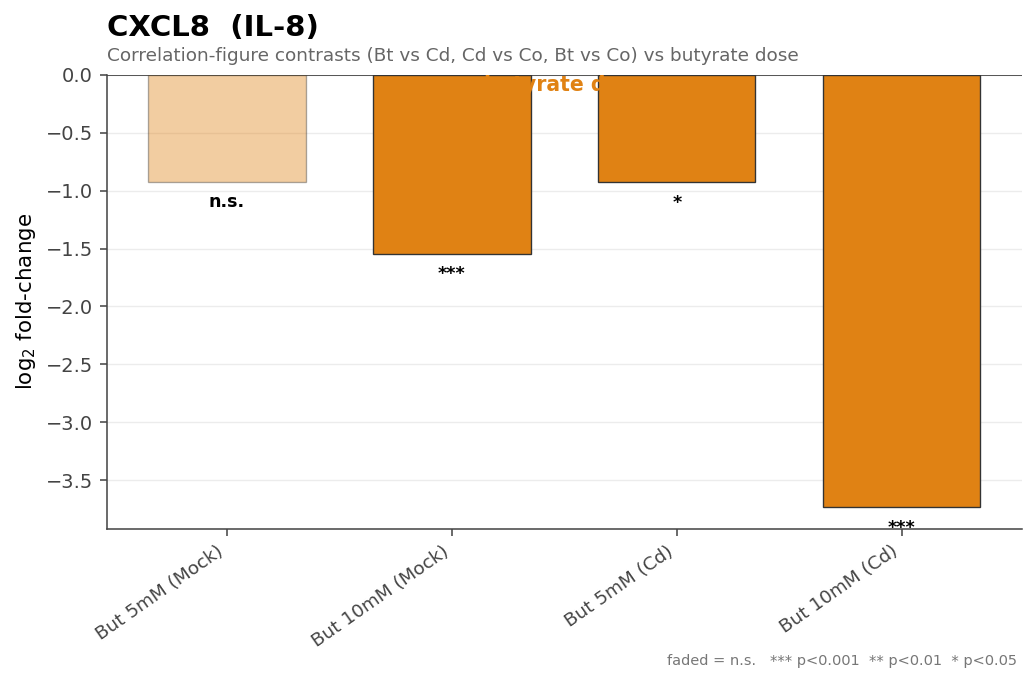

wrote /home/job37yv/Projects_shared/DECIDE_A04_CdiffOrganoid_Butyrate/results/figures/CXCL8_pairwise_vs_butyrate.png


In [4]:
def stars(p):
    if pd.isna(p): return 'n.s.'
    return '***' if p<1e-3 else '**' if p<1e-2 else '*' if p<0.05 else 'n.s.'
order=['co-infection (pairwise)','butyrate dose']
gcol={'co-infection (pairwise)':'#8064a2','butyrate dose':'#e08214'}
df=df.dropna(subset=['lfc']).copy()
df['go']=df.group.map({g:i for i,g in enumerate(order)}); df=df.sort_values('go').reset_index(drop=True)
n=len(df); x=np.arange(n)
alphas=[1.0 if (not pd.isna(p) and p<0.05) else 0.4 for p in df.padj]
fig,ax=plt.subplots(figsize=(max(7.5,0.95*n+2),5.2))
bars=ax.bar(x,df.lfc,color=[gcol[g] for g in df.group],edgecolor='#333',lw=.7,width=.70,zorder=3)
for b,a in zip(bars,alphas): b.set_alpha(a)
for xi,(_,r) in zip(x,df.iterrows()):
    ax.text(xi,r.lfc+(0.1 if r.lfc>=0 else -0.1),stars(r.padj),ha='center',
            va='bottom' if r.lfc>=0 else 'top',fontsize=9,fontweight='bold')
ax.axhline(0,color='#444',lw=.9)
ylo,yhi=ax.get_ylim(); ax.set_ylim(ylo,yhi*1.16)
for g in order:
    sub=df[df.group==g]
    if len(sub)==0: continue
    lo,hi=sub.index.min(),sub.index.max()
    if hi<n-1: ax.axvline(hi+0.5,color='#ccc',ls=(0,(4,3)),lw=1)
    ax.text((lo+hi)/2,ax.get_ylim()[1]*0.96,g,ha='center',va='top',fontsize=10.5,color=gcol[g],fontweight='bold')
ax.set_xticks(x); ax.set_xticklabels(df.label,rotation=35,ha='right',fontsize=9.5)
ax.set_ylabel('log$_2$ fold-change',fontsize=11)
ax.set_title('CXCL8  (IL-8)',fontsize=15,fontweight='bold',loc='left',pad=20)
ax.text(0,1.03,'Correlation-figure contrasts (Bt vs Cd, Cd vs Co, Bt vs Co) vs butyrate dose',
        transform=ax.transAxes,fontsize=9.5,color='#666')
ax.grid(axis='y',color='#ececec',lw=.7,zorder=0)
ax.text(0.995,-0.30,'faded = n.s.   *** p<0.001  ** p<0.01  * p<0.05',transform=ax.transAxes,ha='right',fontsize=7.5,color='#777')
plt.tight_layout(); fig.savefig(FIG/'CXCL8_pairwise_vs_butyrate.png'); plt.show()
print('wrote',FIG/'CXCL8_pairwise_vs_butyrate.png')

## Note
- Purple = the exact pairwise contrasts from the correlation figure (Bt vs Cd, Cd vs Co, Bt vs Co),
  read from the pydeseq2 pairwise DE tables.
- Orange = butyrate-dose effect (A04).
- Cd vs Co is the key one: how much IL-8 differs between Cd-mono and co-infection.
- Swap gene: GENE='HSPA5' etc.